## Load the necessary librabries

In [1]:
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns


## Load model and scaler

In [ ]:
ridge_model = joblib.load(r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\model\ridge_model.pkl")
scaler = joblib.load(r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\model\scaler.pkl")

## Load your test data 

In [ ]:
test_data = pd.read_csv(r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\data\test_data.csv")

# Separate back into X and y
X_test = test_data.drop('price', axis=1)
y_test = test_data['price']


(2850, 6) (2850,)


In [6]:
X_test.head()

,category,bedrooms,bathrooms,amenities,locality,furnished
0,3823.431073,1,1,3500.000000,6049.068085,1
1,3823.431073,1,1,8181.400000,6688.948101,1
2,3823.431073,1,1,5306.266511,2309.756098,0
3,3823.431073,1,1,875.000000,6688.948101,0
4,3823.431073,2,3,5306.266511,1102.487562,2


## Scale test features

In [7]:
X_test_scaled = scaler.transform(X_test)

## Make predictions

In [8]:
y_pred = ridge_model.predict(X_test_scaled)


## Compute Evaluation Metrics

In [9]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: ₵{mae:.2f}")
print(f"RMSE: ₵{rmse:.2f}")
print(f"R² Score: {r2:.3f}")


MAE: ₵2412.99
RMSE: ₵3576.16
R² Score: 0.474


## Compare Predictions vs Actual

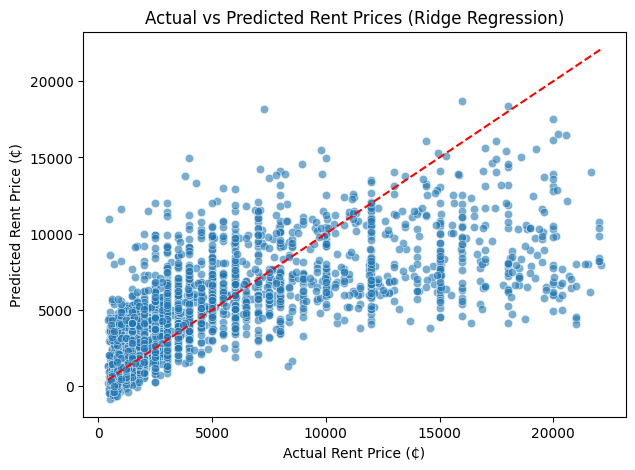

In [10]:
plt.figure(figsize=(7,5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.xlabel("Actual Rent Price (₵)")
plt.ylabel("Predicted Rent Price (₵)")
plt.title("Actual vs Predicted Rent Prices (Ridge Regression)")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.show()


## Residual Analysis

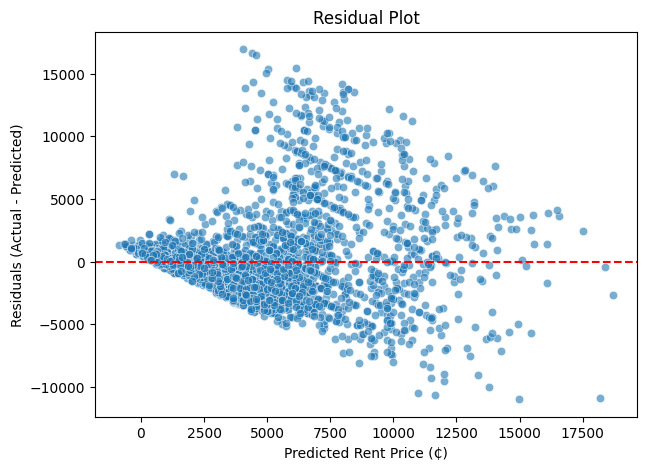

In [11]:
residuals = y_test - y_pred

plt.figure(figsize=(7,5))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Rent Price (₵)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()


## Residual Distribution

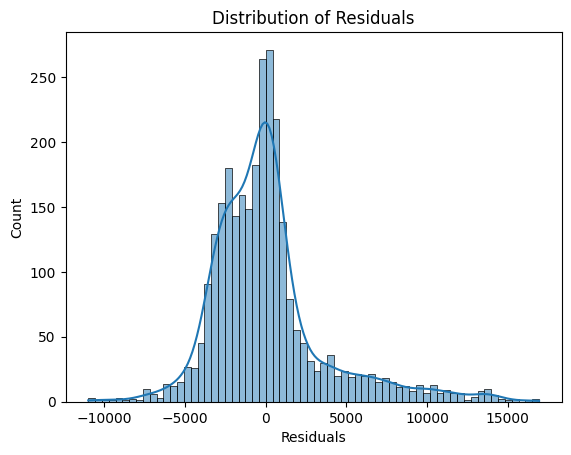

In [12]:
sns.histplot(residuals, kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Residuals")
plt.show()


## Feature Importance (Coefficient Analysis)

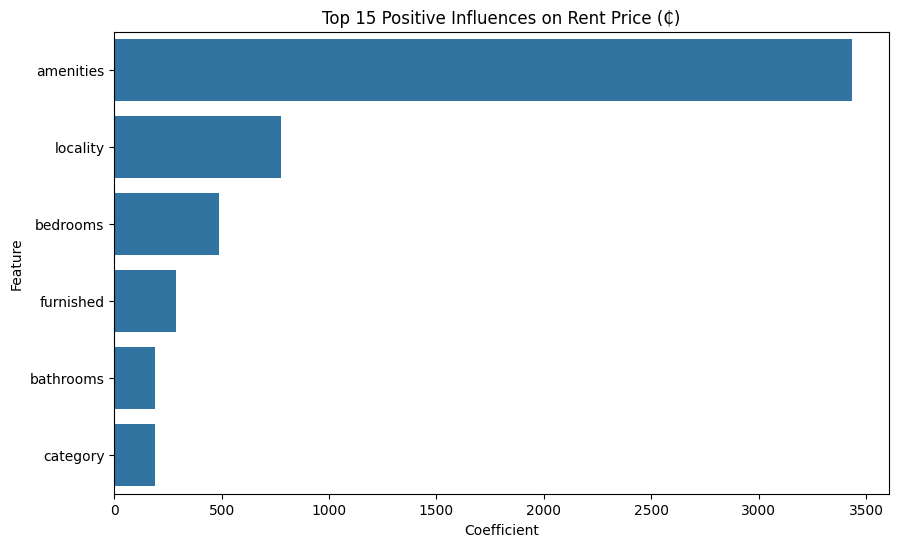

In [15]:


# Load the training data
train_data = pd.read_csv(r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\data\train_data.csv")

# Separate the features and target
X_train = train_data.drop('price', axis=1)  
y_train = train_data['price']

coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': ridge_model.coef_
}).sort_values(by='Coefficient', ascending=False)


plt.figure(figsize=(10,6))
sns.barplot(data=coefficients.head(15), x='Coefficient', y='Feature')
plt.title("Top 15 Positive Influences on Rent Price (₵)")
plt.show()


From this we can confidently say that rent prices are mostly driven by the amenities provided in the house,where the house is located and the number of bedrooms available.

## Model Summary Table

In [17]:
summary = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R²'],
    'Score': [mae, rmse, r2]
})
summary


,Metric,Score
0,MAE,2412.986856
1,RMSE,3576.155800
2,R²,0.473666


In summary, the models prediction is far off by 2,412.97p and 47% of the variation in rent prices is explained by the input variables.

## Cross-validation on Full Data

In [23]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

scores = cross_val_score(ridge_model, X_train_scaled, y_train, cv=5, scoring='r2')
print(f"Cross-validated R²: {scores} ± {scores.std():.3f}")
print("Mean CV R²:", scores.mean())


Cross-validated R²: [0.7819247  0.79452297 0.79164481 0.80942345 0.80663428] ± 0.010
Mean CV R²: 0.7968300412985341


The model produced a cross validated R2 of 0.797,indicating that approximately 80% of the variation in the prices of rent can be explained by the input variables. A standard deviation of 0.010 also indicates that the model is consistent and performs well across different folds. 

## Model Finalization

#### Retrain best model on full training data

In [24]:
ridge_model.fit(X_train, y_train)

,alpha,10
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


### Evaluate on test data

In [25]:
y_pred = ridge_model.predict(X_test)
print("Test R²:", r2_score(y_test, y_pred))

Test R²: 0.47317500507688637


### Save the finalized model

In [27]:
joblib.dump(ridge_model, r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\model\final_model.pkl")


['C:\\Users\\name\\Desktop\\PROJECTS\\My_Projects\\ghana_house_rent_project\\model\\final_model.pkl']

In [29]:
joblib.dump(ridge_model, r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\app\final_model.pkl")

['C:\\Users\\name\\Desktop\\PROJECTS\\My_Projects\\ghana_house_rent_project\\app\\final_model.pkl']